# <center>Finite Element Method: 2D NS equation</center>

# 1. Import necessary packages

In [3]:
import numpy as np
from dolfin import *
from meshio import write
import meshio
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import gmsh
import sys, time, os
from PIL import Image
from scipy.sparse.linalg import eigs
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import inv
from petsc4py import PETSc
import time
# plt.rcParams['font.sans-serif'] = ['SimHei']
# plt.rcParams['axes.unicode_minus'] = False

def process_bar(num, total):
    rate = float(num)/total
    ratenum = int(100*rate)
    rsr = '\r[{}{}]{}%'.format('*'*ratenum,' '*(100-ratenum), ratenum)
    sys.stdout.write(rsr)
    sys.stdout.flush()

set_log_level(LogLevel.ERROR)

/home/kazeyoubi/miniconda3/envs/fenics/lib/python3.11/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# 2. Create mesh

Info    : Meshing 1D...                                                                                                                        
Info    : [  0%] Meshing curve 5 (Ellipse)
Info    : [ 30%] Meshing curve 6 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 70%] Meshing curve 8 (Line)
Info    : [ 90%] Meshing curve 9 (Line)
Info    : Done meshing 1D (Wall 0.000259248s, CPU 0.000248s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.016167s, CPU 0.016858s)
Info    : 1232 nodes 2469 elements


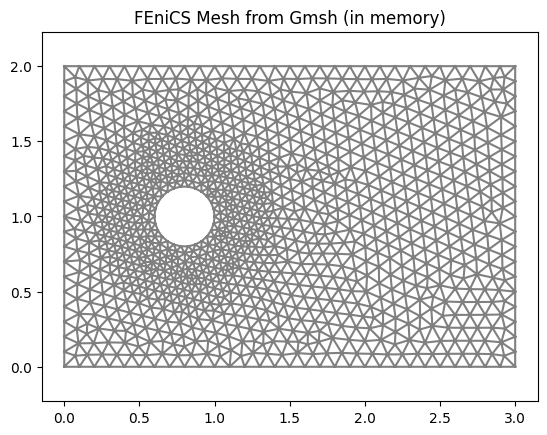

In [4]:
# Define rectangular domain
L = 3.0
H = 2.0

# Define circle
xc = 0.8
yc = 0.5*H
rc = 0.2

mesh_size = 0.1       # mesh size
mesh_size_fine = 0.05
mesh_size_coarse = mesh_size
R_inner = 0.3
R_outer = 0.6

gmsh.initialize()
gmsh.model.add("cylinder")

rect = gmsh.model.occ.addRectangle(0, 0, 0, L, H)
circle = gmsh.model.occ.addDisk(xc, yc, 0, rc, rc)

gmsh.model.occ.cut([(2, rect)], [(2, circle)])
gmsh.model.occ.synchronize()

gmsh.option.setNumber("Mesh.MeshSizeMax", mesh_size)

# Note boundaries
gmsh.model.addPhysicalGroup(2, [rect], name="domain")
boundaries = gmsh.model.getBoundary([(2, rect)], oriented=False)
boundary_lines = {}
curves = gmsh.model.getEntities(1)
tol = 1e-6
for curve in curves:
    dim, tag = curve
    bbox = gmsh.model.getBoundingBox(dim, tag)
    xmin, ymin, zmin, xmax, ymax, zmax = bbox
    
    if abs(ymin) < tol and abs(ymax) < tol:  # y≈0
        boundary_lines["bottom"] = tag
    elif abs(ymin - H) < tol and abs(ymax - H) < tol:  # y≈H
        boundary_lines["top"] = tag
    elif abs(xmin) < tol and abs(xmax) < tol:  # x≈0
        boundary_lines["left"] = tag
    elif abs(xmin - L) < tol and abs(xmax - L) < tol:  # x≈L
        boundary_lines["right"] = tag
    else:
        boundary_lines["hole"] = tag

boundnames = {"bottom": 2, "top": 3, "left": 4, "right": 5, "hole": 6}

for name, tag in boundary_lines.items():
    gmsh.model.addPhysicalGroup(1, [tag], name=name)

hole_curve_tag = boundary_lines["hole"]
distance_field = gmsh.model.mesh.field.add("Distance")
gmsh.model.mesh.field.setNumbers(distance_field, "CurvesList", [hole_curve_tag])

# Local refinement

threshold_field = gmsh.model.mesh.field.add("Threshold")
gmsh.model.mesh.field.setNumber(threshold_field, "IField", distance_field)
gmsh.model.mesh.field.setNumber(threshold_field, "LcMin", mesh_size_fine)
gmsh.model.mesh.field.setNumber(threshold_field, "LcMax", mesh_size_coarse)
gmsh.model.mesh.field.setNumber(threshold_field, "DistMin", R_inner)
gmsh.model.mesh.field.setNumber(threshold_field, "DistMax", R_outer)

gmsh.model.mesh.field.setAsBackgroundMesh(threshold_field)

# Generate 2D mesh
gmsh.model.mesh.generate(2)

node_tags, node_coords, _ = gmsh.model.mesh.get_nodes()
nodes = np.array(node_coords).reshape((-1, 3))[:, :2]

# Obtain triangle unit
element_tags, node_tags = gmsh.model.mesh.get_elements_by_type(2)
cells = np.array(node_tags).reshape(-1, 3) - 1

physical_groups = {}
physicals = gmsh.model.getPhysicalGroups()
for dim, tag in physicals:
    name = gmsh.model.getPhysicalName(dim, tag)
    entities = gmsh.model.getEntitiesForPhysicalGroup(dim, tag)
    physical_groups[name] = {
        "tag": tag,
        "entities": list(entities)
    }

gmsh.finalize()

editor = MeshEditor()
mesh = Mesh()

editor.open(mesh, "triangle", 2, 2)
editor.init_vertices_global(nodes.shape[0], nodes.shape[0])
editor.init_cells_global(cells.shape[0], cells.shape[0])

for i, point in enumerate(nodes):
    editor.add_vertex(i, point)

for i, cell in enumerate(cells):
    editor.add_cell(i, cell)

editor.close()

# print("Number of vertices:", mesh.num_vertices())
# print("Number of cells:", mesh.num_cells())
plot(mesh)
plt.title("FEniCS Mesh from Gmsh (in memory)")
plt.axis("equal")
plt.show()

# 3. Define function space

In [3]:
V = VectorFunctionSpace(mesh,"P", 2)
Q = FunctionSpace(mesh,"P", 1)

# 4. Set boundary conditions

In [4]:
tol = 1E-6

def Bottom(x, on_boundary):
    return on_boundary and near(x[1], 0.0, tol)

def Top(x, on_boundary):
    return on_boundary and near(x[1], H, tol)

def Left(x, on_boundary):
    return on_boundary and near(x[0], 0.0, tol)

def Right(x, on_boundary):
    return on_boundary and near(x[0], L, tol)

def Cylinder(x, on_boundary):
    dist = sqrt((x[0] - xc)**2 + (x[1] - yc)**2)
    return on_boundary and near(dist, rc, 1e-2)

class LeftBound(SubDomain):
    def inside(self, x, on_boundary):
        return near(x[0], 0.0, tol)

class RightBound(SubDomain):
    def inside(self, x, on_boundary):
        return near(x[0], L, tol)

class BottomBound(SubDomain):
    def inside(self, x, on_boundary):
        return near(x[1], 0.0, tol)

class TopBound(SubDomain):
    def inside(self, x, on_boundary):
        return near(x[1], H, tol)

class CylinderBound(SubDomain):
    def inside(self, x, on_boundary, xc=xc, yc=yc):
        dist = sqrt((x[0] - xc)**2 + (x[1] - yc)**2)
        return on_boundary and near(dist, rc, 1e-2)

left = LeftBound()
right = RightBound()
top = TopBound()
bottom = BottomBound()
cylinder = CylinderBound()

# Define mesh functions (for boundary conditions)
boundaries = MeshFunction("size_t", mesh, mesh.topology().dim()-1)
boundaries.set_all(0)
left.mark(boundaries, 1)
right.mark(boundaries, 2)
top.mark(boundaries, 3)
bottom.mark(boundaries, 4)
cylinder.mark(boundaries, 5)

# Define measure for boundary integration
ds = Measure('ds', domain=mesh, subdomain_data=boundaries)

# 5. Define trial and test function

In [5]:
u = TrialFunction(V)
v = TestFunction(V)
p = TrialFunction(Q)
q = TestFunction(Q)

u_n = Function(V)
p_n = Function(Q)
u_mid = Function(V)

# 6. Define weak equation

In [6]:
num_nnlin_iter = 5
prec = "amg" if has_krylov_solver_preconditioner("amg") else "default"

CFL = 0.2
v0 = 1
f = Constant((0, 0))
normal = FacetNormal(mesh)
theta = 0.5
nu = 0

u1 = Function(V)
p1 = Function(Q)
uin = Expression(('v0', 0),v0=v0,H=H, degree=2)
u0 = interpolate(uin, V)
p0 = interpolate(Expression('0', degree=1), Q)
u_n.assign(u0)
p_n.assign(p0)

In [7]:
#dt = CFL*hmesh/np.max(np.abs(u_n.vector().get_local()))
dt = 0.5*mesh.hmin()
print('dt =', dt)

#cb = Expression("abs(sqrt((x[0] - xc)*(x[0] - xc) + (x[1] - yc)*(x[1] - yc)) - rc) < 0.01 ? 1. : 0.", xc=xc, yc=yc, rc=rc, element = Q.ufl_element())

h = CellDiameter(mesh);
u_mag = sqrt(dot(u1,u1))
d1 = 1.0/sqrt((pow(1.0/dt,2.0) + pow(u_mag/h,2.0)))
d2 = h*u_mag

u_mid = theta*u + (1 - theta)*u_n
u_mid1 = theta*u1 + (1 - theta)*u_n

# SUPG stabilization
F_SUPG = d1*inner((u - u_n)/dt + grad(u_mid)*u_mid1 + grad(p_n), grad(v)*u_mid1)*dx + d2*div(u_mid)*div(v)*dx

# PSPG stabilization
F_PSPG = inner(div(u_mid1), q) * dx

Fu = (
    inner((u - u_n)/dt + grad(u_mid)*u_mid1, v)*dx
    - p_n*div(v)*dx # diverges
#    + p_n*inner(normal, v)*ds
    + F_SUPG
)

Fp = (
    d1 * inner((u1 - u_n)/dt + grad(u_mid1)*u_mid1 + grad(p), grad(q))*dx
    # - q*inner(normal, dot(u_n, nabla_grad(u_n)))*ds
    # - q*inner(grad(p_n), normal)*ds
    + F_PSPG
)

auv1 = lhs(Fu)
Lv1 = rhs(Fu)
print("Norm of auv is", assemble(auv1).norm("frobenius"), ", Norm of Lv is", assemble(Lv1).norm("l2"))

auv2 = lhs(Fp)
Lv2 = rhs(Fp)
print("Norm of auv is", assemble(auv2).norm("frobenius"), ", Norm of Lv is", assemble(Lv2).norm("l2"))

dt = 0.019174118594619278
Norm of auv is 5.494877830587965 , Norm of Lv is 5.749791016986976
Norm of auv is 2.482040515776474 , Norm of Lv is 0.6479054200499978


# 7. Computation

For the diffusion equation:

$$
\frac{\partial {u}}{\partial t} - \nu\nabla^2 u = 0
$$

The diffusive speed is $x \sim \sqrt{\nu T}$. Therefore, a rather large $\nu$ should be applied to see the transport clearly.

In [8]:
def getT(j):
    return np.sum(dtlist[:j])

def plotInnerU(ulist, j):
    plt.figure(figsize = (6,4))
    im = plot(inner(ulist[j], ulist[j]))
    plt.title("t = {}".format(getT(j)))
    plt.colorbar(im)

def plotU(ulist, j):
    plt.figure(figsize = (6,4))
    im = plot(ulist[j])
    plt.title("t = {}".format(getT(j)))
    plt.colorbar(im)

In [10]:
T = 1      
#num_steps = int(T/dt)
num_steps = int(1500)
num_pic = int(70)
freq_pic = int(num_steps/num_pic)
hmesh = mesh.hmin()

bcu = [DirichletBC(V, Expression(('v0', 0),v0=v0,H=H, degree=2), Left),
#    DirichletBC(V, Constant((0, 0)), Right),
    DirichletBC(V, Constant((0,0)), Top),
    DirichletBC(V, Constant((0,0)), Bottom),
    DirichletBC(V, Constant((0, 0)), Cylinder),
]

bcp = [#DirichletBC(Q, Expression(('v0', 0),v0=v0,H=H, degree=2), Left),
    DirichletBC(Q, Constant(0), Right),
    # DirichletBC(Q, Constant((0,0)), Top),
    # DirichletBC(Q, Constant((0,0)), Bottom),
#    DirichletBC(V, Constant((0, 0)), Cylinder),
]

bcs = [bcu, bcp]

ulist = [u0]
plist = [p0]
dtlist = [dt]
# u0.rename("Velocity", "velocity field")
# p0.rename("Pressure", "pressure field")
# file_u << u0
# file_p << p0
image_folder_u = './nu_{}_v0_{}_dh_{}/u'.format(nu, v0, hmesh)
image_folder_p = './nu_{}_v0_{}_dh_{}/p'.format(nu, v0, hmesh)
os.makedirs(image_folder_u, exist_ok = True)
os.makedirs(image_folder_p, exist_ok = True)

num_nnlin_iter = 5
prec = "amg" if has_krylov_solver_preconditioner("amg") else "default"

for j in range(num_steps):

    for k in range(5):
        A1 = assemble(auv1)
        b1 = assemble(Lv1)
        [bc.apply(A1, b1) for bc in bcu]
        [bc.apply(u1.vector()) for bc in bcu]
        # solve(A1, u1.vector(), b1, "gmres", "ilu")
        solve(A1, u1.vector(), b1, "bicgstab", "default")
        # u1.rename("Velocity", "velocity field")

        A2 = assemble(auv2)
        b2 = assemble(Lv2)
        [bc.apply(A2, b2) for bc in bcp]
        [bc.apply(p1.vector()) for bc in bcp]
        # solve(A2, p1.vector(), b2, "gmres", "ilu")
        solve(A2, p1.vector(), b2, "bicgstab", "default")
        p_n.assign(p1)
        # p1.rename("Pressure", "pressure field")
        # file_p << p1
        # file_u << u1
    
    ulist.append(Function(V))
    ulist[-1].assign(u1)
    u_n.assign(u1)
    
    plist.append(Function(Q))
    plist[-1].assign(p1)
    p_n.assign(p1)
#    dt = CFL*hmesh/np.max(np.abs(u_n.vector().get_local()))
    dtlist.append(dt)

    if j % freq_pic == 0:
        plotInnerU(ulist, j)
        plt.savefig('./nu_{}_v0_{}_dh_{}/u/u_{}.png'.format(nu, v0, hmesh, j))
        plt.close(1)

        plotU(plist, j)
        plt.savefig('./nu_{}_v0_{}_dh_{}/p/p_{}.png'.format(nu, v0, hmesh, j))
        plt.close(1)
    
    process_bar(j+1,num_steps)

[****************************************************************************************************]100%

# 8. Postprocess

For a body surrounded by the fluid, the net force can be expressed as

$$
\mathbf{F} = \int_{\partial\Omega} (-p \mathbf{I} + \nu \nabla \mathbf{u}) \cdot \mathbf{n} \, ds
$$

Then the lift coefficient $ C_L $ and drag coefficient $ C_D $ are respectively

$$
C_L = \frac{F_L}{\frac{1}{2}\rho U^2A},\quad C_D = \frac{F_D}{\frac{1}{2}\rho U^2A}
$$

where $ F_L $ is the lift force, the vertical component of $ \mathbf{F} $; $ F_D $ is the drag force, the horizontal component of $ \mathbf{F} $; $ A $ is the reference area, calculated by diameter of cylinder times the length unit.

In [11]:
CDlist = []
CLlist = []

for j in range(num_steps):

    rho = 1000
    AA = 2 * rc * H
    e_x = as_vector((1.0, 0.0))
    e_y = as_vector((0.0, 1.0))
    F = -plist[j] * normal
    F_D = dot(F, e_x) * ds(5)
    F_L = dot(F, e_y) * ds(5)
    
    drag = assemble(F_D)
    lift = assemble(F_L)
    
    CDlist.append(drag / (0.5 * rho * v0**2 * H))
    CLlist.append(lift / (0.5 * rho * v0**2 * H))

# 9. Plot

In [5]:
output_gif_u = 'u_nu_{}_v0_{}_dh_{}.gif'.format(nu, v0, hmesh)
output_gif_p = 'p_nu_{}_v0_{}_dh_{}.gif'.format(nu, v0, hmesh)

images_u = []
for j in range(num_steps): 
    filename = './nu_{}_v0_{}_dh_{}/u/u_{}.png'.format(nu, v0, hmesh, j)
    try:
        img = Image.open(filename)
        images_u.append(img)
    except FileNotFoundError:
        continue
#        print(f"Warning: File {filename} doesn't exist, skip")

def fileName(base_filename):
    filename, _ = os.path.splitext(base_filename)
    counter = 0
    output_filename = base_filename
    while os.path.exists(output_filename):
        counter += 1
        output_filename = "{}_{}.gif".format(filename, counter)
    return output_filename

# Save as GIF
if images_u:
    images_u[0].save(
        fileName(output_gif_u),
        save_all=True,
        append_images=images_u[1:],
        duration=100,   # Display time per frame (milliseconds)
        loop=0,         # Number of loops, 0 means infinite loop
        disposal=2     
    )
    print(f"GIF has been generated: {fileName(output_gif_u)}")
else:
    print("No pictures for genrating GIF!")

images_p = []
for j in range(num_steps): 
    filename = './nu_{}_v0_{}_dh_{}/p/p_{}.png'.format(nu, v0, hmesh, j)
    try:
        img = Image.open(filename)
        images_p.append(img)
    except FileNotFoundError:
        continue
#        print(f"Warning: File {filename} doesn't exist, skip")

# Save as GIF
if images_p:
    images_p[0].save(
        fileName(output_gif_p),
        save_all=True,
        append_images=images_p[1:],
        duration=100,   # Display time per frame (milliseconds)
        loop=0,         # Number of loops, 0 means infinite loop
        disposal=2 
    )
    print(f"GIF has been generated: {fileName(output_gif_p)}")
else:
    print("No pictures for genrating GIF!")

NameError: name 'nu' is not defined

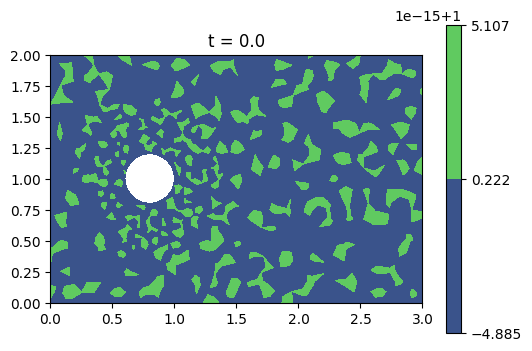

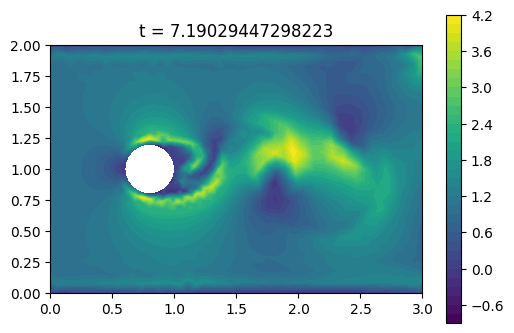

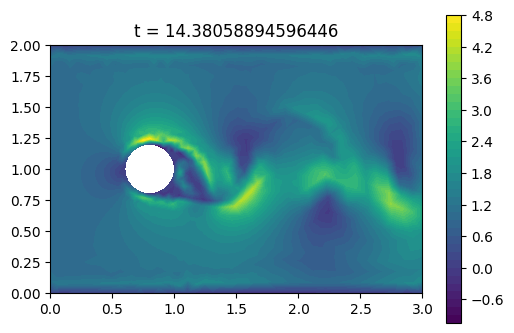

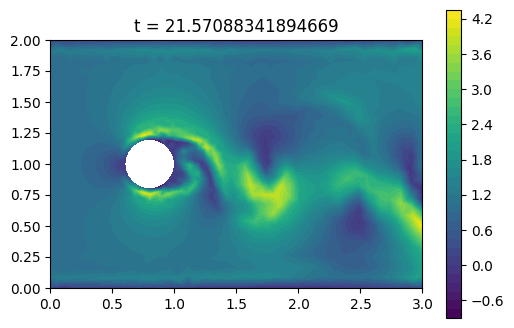

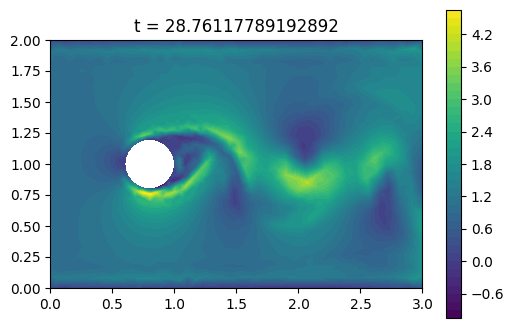

In [13]:
plotInnerU(ulist, 0)
plotInnerU(ulist, int(len(ulist)*1/4))
plotInnerU(ulist, int(len(ulist)*2/4))
plotInnerU(ulist, int(len(ulist)*3/4))
plotInnerU(ulist, len(ulist)-1)

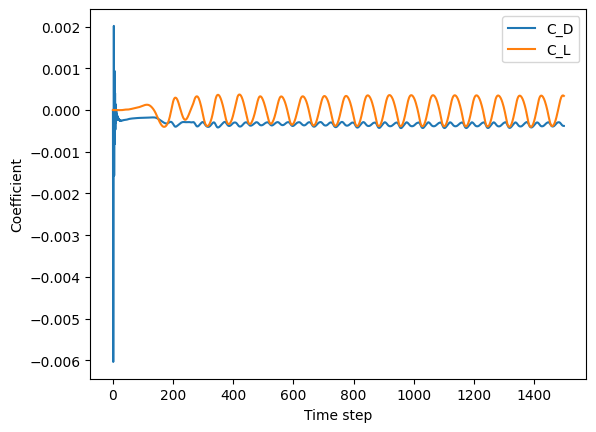

In [14]:
plt.figure()
plt.plot(CDlist, label="C_D")
plt.plot(CLlist, label="C_L")
plt.xlabel("Time step")
plt.ylabel("Coefficient")
plt.legend()

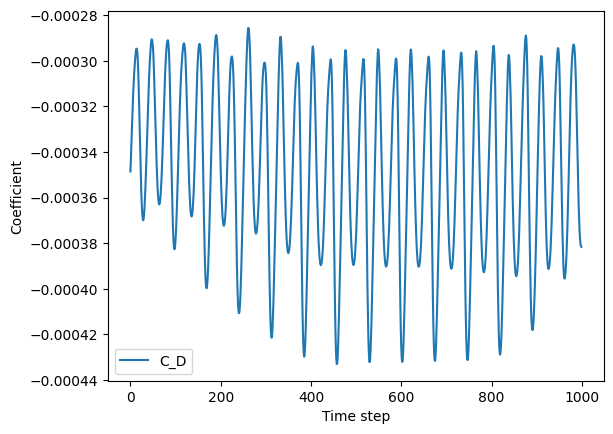

In [15]:
plt.figure()
plt.plot(CDlist[500:], label="C_D")
plt.xlabel("Time step")
plt.ylabel("Coefficient")
plt.legend()